# Reproduce & Extend: Quantitative Trading with Machine Learning
UE24CS352A Machine Learning - Mini-Project | Team: Zia (PES2UG24CS620), [teammate name / SRN]

Reference: R. Glawion, *Quantitative Trading with Machine Learning* (Stanford CS229); data from https://github.com/rglawion/cs229_project_report.

**Part 1** reproduces Elastic Net, Decision Tree, XGBoost, LightGBM. **Part 2** adds **RBF Support Vector Regression (SVR)**.

**How to use:** `Run all` works as is (about 1 min) - it loads the saved predictions in `results/`. Set `RUN_FULL = True` to retrain everything (several hours on one CPU).

In [1]:
import itertools, glob, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from datetime import datetime
from dateutil.relativedelta import relativedelta, FR
from sklearn.linear_model import ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
import xgboost as xgb, lightgbm as lgb
warnings.filterwarnings("ignore")

RUN_FULL = False        # False: load saved predictions from results/ ; True: retrain all models (hours)
HORIZONS = [1, 5, 20]   # poster horizons
MODELS = ["Elastic Net", "Decision Tree", "XGBoost", "LightGBM", "SVR"]

## 1. Data and features
31 stocks (VW + 30 suppliers) x 27 daily-return lags + 13 macro variables = **850 features**. Missing values are set to 0, as in the paper. Target: VW return over the next *h* days.

In [2]:
MACRO = ["euribor_3m", "eurirs_10y", "itraxx_crossover1", "itraxx_crossover1_relDiff1", "itraxx_crossover1_relDiff6",
         "euribor_3m_relDiff1", "eurirs_10y_relDiff1", "euribor_3m_relDiff6", "eurirs_10y_relDiff6",
         "OutputGap", "CPI_x", "bund_y10_x", "ISwap_y10_x"]
d = pd.read_parquet("data/databaseFrankfurtComplete.parquet")
d["Date"] = pd.to_datetime(d["Date"].dt.date); d.index = d["Date"]
tick = [c[len("Return_Delta1_"):] for c in d.columns if c.startswith("Return_Delta1_")]
feats = [f"Return_Delta{i}_{t}" for t in tick for i in range(1, 28)] + MACRO
X = d[feats].replace([np.inf, -np.inf], np.nan).fillna(0).astype(np.float32)
ys = {h: d[f"Return_Future_Delta{h}_VW"] for h in [1, 5, 10, 15, 20, 25]}
print(X.shape, "| days:", X.index.min().date(), "to", X.index.max().date())

(3809, 850) | days: 2005-01-03 to 2019-12-30


## 2. Rolling validation (as in the paper)
5 years training, 1 year validation (hyper-parameter selection), 1 month out-of-sample test; roll forward one month -> **109 refits**, never shuffled.

In [3]:
START = datetime(2010, 1, 1)
N_STEPS = int(np.floor((X.index[-1] - START).days / 30.436875)) - 10     # = 109

def window(m):
    tr = START + relativedelta(months=m, day=31, weekday=FR(-1))
    va = tr + relativedelta(months=12, day=31, weekday=FR(-1))
    te = va + relativedelta(months=1, day=31, weekday=FR(-1))
    i = X.index
    return (i < tr), ((i > tr) & (i < va)), ((i > va) & (i < te)), va

# Reduced grids (one CPU). tune_every = re-run the grid search every k monthly refits (paper: every month, larger grids).
CFG = {
 "Elastic Net":   dict(mk=lambda **p: ElasticNet(**p), tune_every=1, grid=dict(alpha=np.logspace(-6, -1, 6), l1_ratio=[0.5, 1.0])),
 "Decision Tree": dict(mk=lambda **p: DecisionTreeRegressor(random_state=0, **p), tune_every=1,
                       grid=dict(max_depth=[4, 10, 20], min_samples_split=[2, 10], min_samples_leaf=[2, 8], max_features=["sqrt", "log2"])),
 "XGBoost":  dict(mk=lambda **p: xgb.XGBRegressor(n_jobs=1, tree_method="hist", max_bin=64, random_state=0, **p), tune_every=12,
                  grid=dict(max_depth=[3, 6], learning_rate=[0.05, 0.1], n_estimators=[50, 100])),
 "LightGBM": dict(mk=lambda **p: lgb.LGBMRegressor(n_jobs=1, verbose=-1, random_state=0, max_bin=63, colsample_bytree=0.5, **p), tune_every=6,
                  grid=dict(max_depth=[3, 6, 12], learning_rate=[0.05, 0.1], n_estimators=[50, 100], num_leaves=[11, 31])),
 "SVR (new)": dict(mk=lambda **p: SVR(kernel="rbf", gamma="scale", **p), tune_every=6, scale=True,
                   grid=dict(C=[0.1, 1, 10], epsilon=[0.001, 0.01])),
}
CFG["SVR"] = CFG["SVR (new)"]

def tune_fit(cfg, Xtr, ytr, Xva, yva, best=None):
    if best is None:
        grid = [dict(zip(cfg["grid"], v)) for v in itertools.product(*cfg["grid"].values())]
        best = min(grid, key=lambda p: np.mean((yva - cfg["mk"](**p).fit(Xtr, ytr).predict(Xva)) ** 2))
    return cfg["mk"](**best).fit(Xtr, ytr), best

def get_window(cfg, h, m):
    ok = ys[h].notna().values
    itr, iva, ite, vdate = window(m); itr, iva, ite = itr & ok, iva & ok, ite & ok
    Xtr, Xva, Xte = X.values[itr], X.values[iva], X.values[ite]
    if cfg.get("scale"):
        sc = StandardScaler().fit(Xtr); Xtr, Xva, Xte = sc.transform(Xtr), sc.transform(Xva), sc.transform(Xte)
    y = ys[h].values
    return Xtr, y[itr], Xva, y[iva], Xte, y[ite], X.index[ite], vdate

def run_model(model, h):
    cfg, rows, best = CFG[model], [], None
    for m in range(N_STEPS):
        if window(m)[2].sum() == 0: continue          # data ends Dec-2019
        Xtr, ytr, Xva, yva, Xte, yte, dates, vdate = get_window(cfg, h, m)
        t0 = time.time()
        est, best = tune_fit(cfg, Xtr, ytr, Xva, yva, best if m % cfg["tune_every"] else None)
        dur = time.time() - t0; yhat = est.predict(Xte)
        rows += [dict(model=model, day=h, date=vdate, predicted_date=a, y=b, yhat=c, err=b - c, time=dur, params=str(best)) for a, b, c in zip(dates, yte, yhat)]
    return pd.DataFrame(rows)

import os; os.makedirs("results", exist_ok=True)
if RUN_FULL:
    for model in ["Elastic Net", "Decision Tree", "XGBoost", "LightGBM", "SVR"]:
        for h in HORIZONS:
            f = f"results/{model.replace(' ', '')}_h{h}.parquet"
            if not os.path.exists(f): run_model(model, h).to_parquet(f); print("saved", f)

## 3. Quick demo: all five models on ONE window (about 1 minute)
A single window has only ~19 test days, so its ranking is noisy; the real comparison is the 109-window average below.

In [4]:
h, m = 5, 60
print(f"window {m}, horizon h={h}")
for name in MODELS:
    cfg = CFG[name]; Xtr, ytr, Xva, yva, Xte, yte, dates, vdate = get_window(cfg, h, m)
    t0 = time.time(); est, best = tune_fit(cfg, Xtr, ytr, Xva, yva)
    print(f"{name:14s} test RMSE {np.sqrt(np.mean((yte - est.predict(Xte)) ** 2)):.4f}   {time.time() - t0:5.1f}s   {best}")

window 60, horizon h=5


Elastic Net    test RMSE 0.0756     1.0s   {'alpha': np.float64(0.01), 'l1_ratio': 1.0}


Decision Tree  test RMSE 0.1031     0.9s   {'max_depth': 20, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'log2'}


XGBoost        test RMSE 0.0754    16.1s   {'max_depth': 6, 'learning_rate': 0.05, 'n_estimators': 50}


LightGBM       test RMSE 0.0771    15.0s   {'max_depth': 6, 'learning_rate': 0.05, 'n_estimators': 50, 'num_leaves': 11}


SVR            test RMSE 0.0776    14.9s   {'C': 0.1, 'epsilon': 0.01}


## 4. Part 1: Reproduction - prediction error (paper vs ours)
Paper metric = mean of the monthly test RMSEs (as in the author's code); the pooled RMSE over all test days is shown as well.

In [5]:
RES = pd.concat([pd.read_parquet(f) for f in glob.glob("results/*_h*.parquet")]); RES["model"] = RES["model"]
PAPER_RMSE = {"Elastic Net": {1: .0174, 5: .0401, 20: .0751}, "Decision Tree": {1: .0190, 5: .0422, 20: .0952},
              "XGBoost": {1: .0176, 5: .0410, 20: .0850}, "LightGBM": {1: .0177, 5: .0408, 20: .0815}}
rows = []
for model in MODELS:
    for h in HORIZONS:
        g = RES[(RES.model == model) & (RES.day == h)]
        w = g.assign(e2=g.err ** 2, ae=g.err.abs()).groupby("date")
        rmse, mae = np.sqrt(w.e2.transform("mean")).mean(), w.ae.transform("mean").mean()
        p = PAPER_RMSE.get(model, {}).get(h)
        rows.append(dict(model=model + (" (new)" if model == "SVR" else ""), h=h, paper_RMSE=p, our_RMSE=round(rmse, 4),
                         diff_pct=None if p is None else round((rmse / p - 1) * 100, 1), our_MAE=round(mae, 4),
                         pooled_RMSE=round(np.sqrt((g.err ** 2).mean()), 4), test_days=len(g)))
T1 = pd.DataFrame(rows); T1

,model,h,paper_RMSE,our_RMSE,diff_pct,our_MAE,pooled_RMSE,test_days
0,Elastic Net,1,0.0174,0.0174,0.1,0.0137,0.0191,2156
1,Elastic Net,5,0.0401,0.0401,-0.1,0.0327,0.0460,2156
2,Elastic Net,20,0.0751,0.0754,0.4,0.0668,0.0903,2156
3,Decision Tree,1,0.0190,0.0175,-8.0,0.0138,0.0192,2156
4,Decision Tree,5,0.0422,0.0407,-3.5,0.0326,0.0473,2156
5,Decision Tree,20,0.0952,0.0824,-13.5,0.0689,0.1014,2156
6,XGBoost,1,0.0176,0.0179,1.9,0.0141,0.0196,2156
7,XGBoost,5,0.0410,0.0420,2.5,0.0346,0.0480,2156
8,XGBoost,20,0.0850,0.0857,0.8,0.0754,0.1056,2156
9,LightGBM,1,0.0177,0.0179,0.9,0.0141,0.0196,2156


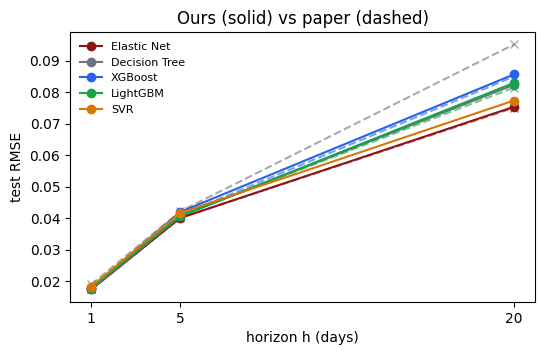

In [6]:
col = {"Elastic Net": "#8C1515", "Decision Tree": "#6b7280", "XGBoost": "#2563eb", "LightGBM": "#16a34a", "SVR": "#d97706"}
fig, ax = plt.subplots(figsize=(6, 3.5))
for model in MODELS:
    g = T1[T1.model.str.startswith(model)]; ax.plot(g.h, g.our_RMSE, "-o", color=col[model], label=model)
    if model in PAPER_RMSE: ax.plot(HORIZONS, [PAPER_RMSE[model][h] for h in HORIZONS], "--x", color=col[model], alpha=.6)
ax.set_xticks(HORIZONS); ax.set_xlabel("horizon h (days)"); ax.set_ylabel("test RMSE"); ax.set_title("Ours (solid) vs paper (dashed)"); ax.legend(frameon=False, fontsize=8); plt.show()

## 5. Trading strategy
EUR 1,000, one share, long if forecast > threshold, short if < threshold, no transaction costs (the author's rule).
**Check:** fed with the author's own saved predictions and his exact ordering, our simulator should reproduce the paper's Table 2.

In [7]:
THR = [0.0, 0.0025, 0.005, 0.01]
px = pd.read_parquet("data/databaseFrankfurt.parquet"); px = px[px["Ticker"] == "VOW.F"]; px.index = pd.to_datetime(px.index.date); px = px["Close"]

def simulate(yhat, p, thr):
    lp = sp = None; cash = 1000.0; n = 0; acct = cash
    for t in range(len(p)):
        if np.isnan(p[t]): break
        if lp is None and yhat[t] > thr: lp = p[t]; n += 1
        if sp is None and yhat[t] < thr: sp = p[t]; n += 1
        if lp is not None and yhat[t] < thr: cash += p[t] - lp; lp = None; n += 1
        if sp is not None and yhat[t] > thr: cash += sp - p[t]; sp = None; n += 1
        acct = cash + (p[t] - lp if lp is not None else 0) + (sp - p[t] if sp is not None else 0)
        if acct <= 0: break
    return (acct / 1000 - 1) * 100, n

def strategy(g, h):          # g sorted in the desired order
    yhat = g["yhat"].reset_index(drop=True).values
    p = px[px.index.isin(g["predicted_date"].values)].sort_index().reset_index(drop=True).shift(-h).values
    T = len(p) - h
    return [simulate(yhat[:T], p[:T], c) for c in THR], (p[T - 1] - p[0]) / 10      # buy & hold in % of EUR 1,000

# --- validation against the paper's Table 2 (author's predictions, author's ordering) ---
A = pd.read_parquet("data/author_Summary_Results_Testset.parquet")
A["predicted_date"] = pd.to_datetime(A.predicted_date.dt.date); A["date"] = pd.to_datetime(A.date.dt.date)
paper = pd.read_csv("data/paper_table2.csv"); nm = {"Decision Tree Regressor": "Decision Tree", "Light GBM": "LightGBM"}
bad = 0
for m_ in A.model.unique():
    for h in sorted(A.day.unique()):
        g = A[A.model == m_].sort_values(by=["date"]); g = g[g.day == h].sort_values(by=["date"])
        res, _ = strategy(g, h)
        ref = paper[(paper.model == nm.get(m_, m_)) & (paper.h == h)].sort_values("threshold")
        bad += sum(abs(r[0] - p) > 0.006 or r[1] != n for r, p, n in zip(res, ref.reported_profit, ref.reported_trades))
print("cells that differ from the paper's Table 2:", bad, "of 96")

cells that differ from the paper's Table 2: 0 of 96


### Our predictions: profit at each threshold (chronological order)
The author's code orders each month's predictions with an unstable sort, so his profits depend on an arbitrary within-month order; we use chronological order.

In [8]:
rows = []
for model in MODELS:
    for h in HORIZONS:
        g = RES[(RES.model == model) & (RES.day == h)].sort_values("predicted_date")
        res, bh = strategy(g, h)
        r = dict(model=model, h=h, buy_hold=round(bh, 2))
        for c, (pf, n) in zip(THR, res): r[f"profit_c{c}"] = round(pf, 2); r[f"trades_c{c}"] = n
        rows.append(r)
T2 = pd.DataFrame(rows)
pd.set_option("display.width", 250); T2

,model,h,buy_hold,profit_c0.0,trades_c0.0,profit_c0.0025,trades_c0.0025,profit_c0.005,trades_c0.005,profit_c0.01,trades_c0.01
0,Elastic Net,1,7.82,20.58,111,-7.83,21,-7.99,5,-7.82,1
1,Elastic Net,5,7.82,8.37,229,13.67,151,-1.16,115,-8.56,51
2,Elastic Net,20,8.02,15.28,75,12.94,67,11.28,71,7.12,55
3,Decision Tree,1,7.82,-8.98,137,-7.04,53,-6.75,49,-6.49,33
4,Decision Tree,5,7.82,-8.64,97,-9.70,93,-9.70,93,-9.31,65
5,Decision Tree,20,8.02,-23.69,441,-24.82,437,-30.12,429,-23.48,365
6,XGBoost,1,7.82,-18.67,1251,-10.36,573,-2.26,277,-7.83,85
7,XGBoost,5,7.82,4.61,655,-2.20,643,0.22,607,-3.55,531
8,XGBoost,20,8.02,6.10,243,7.55,263,7.53,259,8.98,311
9,LightGBM,1,7.82,-24.27,1307,-13.70,653,-9.36,449,-6.05,169


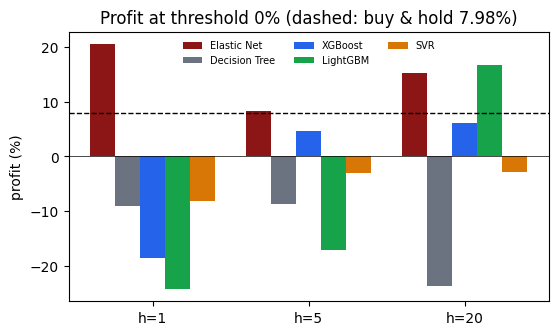

Elastic Net h=20, c=0:  paper +21.49 | author's predictions, chronological: 19.98 | ours, chronological: 15.28


In [9]:
fig, ax = plt.subplots(figsize=(6.2, 3.5)); w = .16
for i, model in enumerate(MODELS):
    g = T2[T2.model == model]; ax.bar(np.arange(3) + (i - 2) * w, g["profit_c0.0"], w, color=col[model], label=model)
ax.axhline(7.98, color="k", ls="--", lw=1); ax.axhline(0, color="k", lw=.5)
ax.set_xticks(range(3)); ax.set_xticklabels([f"h={h}" for h in HORIZONS]); ax.set_ylabel("profit (%)")
ax.set_title("Profit at threshold 0% (dashed: buy & hold 7.98%)"); ax.legend(frameon=False, fontsize=7, ncol=3); plt.show()

# headline cell: Elastic Net, h=20, threshold 0
print("Elastic Net h=20, c=0:  paper +21.49 | author's predictions, chronological:",
      round(strategy(A[(A.model == "Elastic Net") & (A.day == 20)].sort_values("predicted_date"), 20)[0][0][0], 2),
      "| ours, chronological:", T2[(T2.model == "Elastic Net") & (T2.h == 20)]["profit_c0.0"].iloc[0])

## 6. Part 2: the new model (SVR) vs the reference models
**Why SVR:** not used or mentioned in the paper; small, high-dimensional data (1.3-3k rows, 850 features) suits kernel methods; it is a smooth non-linear regulariser, unlike the linear Elastic Net or the tree models.
**Result:** worse than Elastic Net at every horizon (+3% to +5% RMSE), similar to XGBoost/LightGBM at h=1 and 5, better than Decision Tree, XGBoost and LightGBM at h=20 (second best overall). Our (untested) interpretation: the signal is weak and noisy, so strongly regularised smooth models do best; SVR lacks Elastic Net's feature selection across 850 correlated inputs.

In [10]:
T1[T1.h.isin(HORIZONS)].pivot(index="model", columns="h", values="our_RMSE").loc[[m + (" (new)" if m == "SVR" else "") for m in MODELS]]

h,1,5,20
model,,,
Elastic Net,0.0174,0.0401,0.0754
Decision Tree,0.0175,0.0407,0.0824
XGBoost,0.0179,0.0420,0.0857
LightGBM,0.0179,0.0406,0.0830
SVR (new),0.0183,0.0417,0.0774


## 7. Conclusions and limitations
1. The prediction results reproduce: Elastic Net is the most accurate model at h = 1, 5, 20 (within 0.4% of the paper).
2. The added SVR is competitive but does not beat Elastic Net.
3. The paper's trading claims need care: they depend on within-month ordering, h = 1 and 5 are unstable, and only h = 20 shows a consistent edge (about 2x buy and hold, before costs).

**Deviations:** smaller hyper-parameter grids and less frequent re-tuning for XGBoost/LightGBM (one CPU instead of the author's 64 cores / ~36 h); only h = 1, 5, 20 (poster horizons); one random seed; no transaction costs or risk measures; timings are not comparable with the paper's.